# 04. 종목마다 맞는 피타고라스 지수는 다르다

01~03에서는 강의처럼 모든 종목에 **지수 2**를 썼다.

$$\text{기대 승률} = \frac{\text{득점}^k}{\text{득점}^k + \text{실점}^k}, \quad k = 2$$

그런데 NBA 결과를 보면 기대 승률이 0.49~0.56 사이에 몰려 있고, 실제 승률(0.28~0.83)과 범위가 크게 다르다. 농구는 점수가 많이 나서 득실점 차이가 비율로 보면 작기 때문이다.
그래서 **2025 시즌 데이터로 종목마다 실제 승률에 가장 잘 맞는 지수 k를 직접 찾아본다.**

- 축구는 무승부가 있어서 승률 대신 **승점 비율**(얻은 승점 ÷ 최대 승점)을 쓴다.
- '가장 잘 맞는다' = 실제 승률과 기대 승률의 제곱오차가 가장 작다.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.optimize import minimize_scalar
for f in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK JP"]:
    if any(f in x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False

def team_games(df, home, away, hs, as_, date, dayfirst=False):
    """경기 기록을 '팀별 경기' 형태로 펼친다 (홈 경기 + 원정 경기)."""
    h = pd.DataFrame({"team": df[home], "F": df[hs], "A": df[as_], "date": df[date]})
    a = pd.DataFrame({"team": df[away], "F": df[as_], "A": df[hs], "date": df[date]})
    g = pd.concat([h, a], ignore_index=True)
    g["date"] = pd.to_datetime(g["date"], dayfirst=dayfirst)
    return g

def season_table(g):
    """팀별 경기 수, 승률, 득점, 실점"""
    return g.groupby("team").agg(G=("res", "size"), wpc=("res", "mean"), F=("F", "sum"), A=("A", "sum"))

def pyth(F, A, k=2.0):
    return F**k / (F**k + A**k)

def best_k(t):
    """실제 승률과의 제곱오차가 가장 작은 지수 k"""
    return minimize_scalar(lambda k: ((t.wpc - pyth(t.F, t.A, k))**2).mean(), bounds=(0.5, 30), method="bounded").x

# 데이터 불러오기
mlb = pd.read_excel("../data/mlb-2025-asplayed.xlsx", sheet_name="As-Played Schedule")
MG = team_games(mlb, "Home", "Away", "Home Score", "Away Score", "Date")
MG["res"] = (MG.F > MG.A).astype(float)                       # 야구: 승 1, 패 0

eng = pd.read_excel("../data/epl-2025-asplayed.xlsx")
EG = team_games(eng, "HomeTeam", "AwayTeam", "FTHG", "FTAG", "Date", dayfirst=True)
EG["div"] = pd.concat([eng.Div, eng.Div], ignore_index=True)
EG["res"] = np.where(EG.F > EG.A, 1, np.where(EG.F == EG.A, 1/3, 0))   # 축구: 승점 비율 (승 3, 무 1)

nba = pd.read_excel("../data/nba-2025-asplayed.xlsx")
NBA = pd.DataFrame({"G": 82, "wpc": nba.Wins / 82, "F": nba.Points_For, "A": nba.Points_Against}).set_index(nba.Team)
MLB, ENG = season_table(MG), season_table(EG)
print(f"MLB {len(MLB)}팀 {len(mlb)}경기 | NBA {len(NBA)}팀 | 잉글랜드 1~4부 {len(ENG)}팀 {len(eng)}경기")

MLB 30팀 2430경기 | NBA 30팀 | 잉글랜드 1~4부 92팀 2036경기


In [2]:
rows = []
for name, t in [("MLB 2025", MLB), ("NBA 2024-25", NBA), ("잉글랜드 축구 2024-25", ENG)]:
    k = best_k(t)
    for label, kk in [("k = 2", 2.0), (f"최적 k = {k:.2f}", k)]:
        err = t.wpc - pyth(t.F, t.A, kk)
        rmse = np.sqrt((err**2).mean())
        rows.append({"리그": name, "지수": label, "승률 오차(RMSE)": rmse,
                     "시즌 기준 오차": rmse * t.G.mean(), "상관계수": np.corrcoef(t.wpc, pyth(t.F, t.A, kk))[0, 1]})
res = pd.DataFrame(rows).set_index(["리그", "지수"])
res.style.format({"승률 오차(RMSE)": "{:.3f}", "시즌 기준 오차": "{:.1f}", "상관계수": "{:.3f}"})

`시즌 기준 오차`는 승률 오차를 경기 수로 환산한 값이다 (야구·농구: 승수, 축구: 승점÷3).

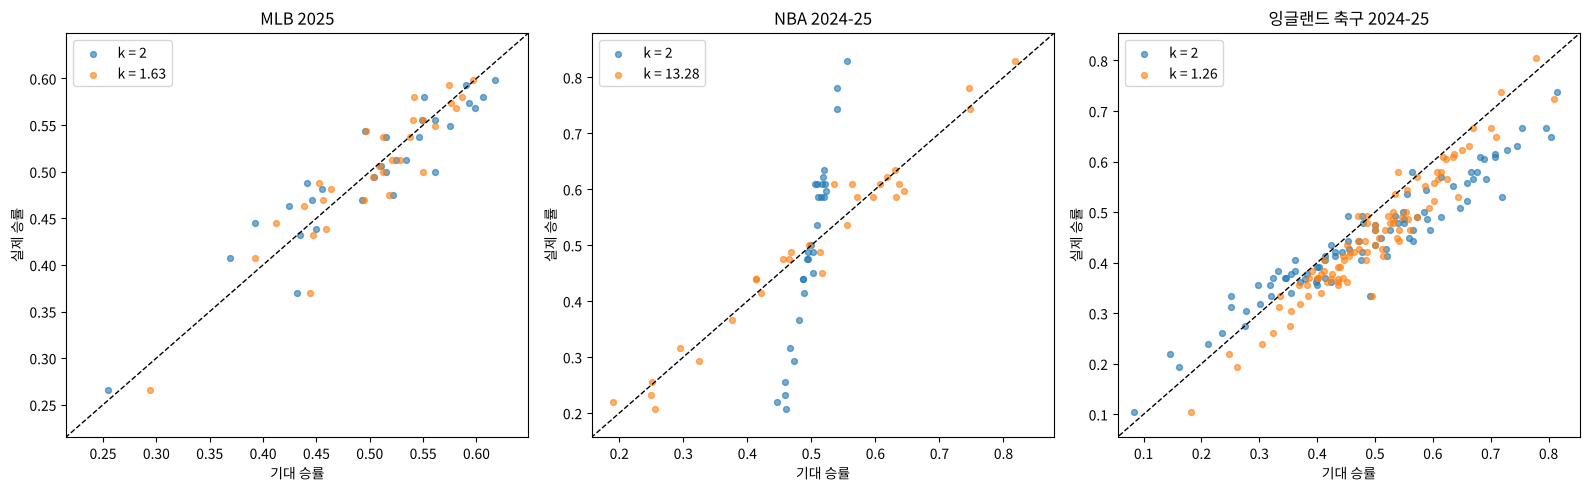

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, t) in zip(axes, [("MLB 2025", MLB), ("NBA 2024-25", NBA), ("잉글랜드 축구 2024-25", ENG)]):
    k = best_k(t)
    ax.scatter(pyth(t.F, t.A, 2), t.wpc, s=18, alpha=0.6, label="k = 2")
    ax.scatter(pyth(t.F, t.A, k), t.wpc, s=18, alpha=0.6, label=f"k = {k:.2f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    lo, hi = t.wpc.min() - 0.05, t.wpc.max() + 0.05
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("기대 승률"); ax.set_ylabel("실제 승률"); ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

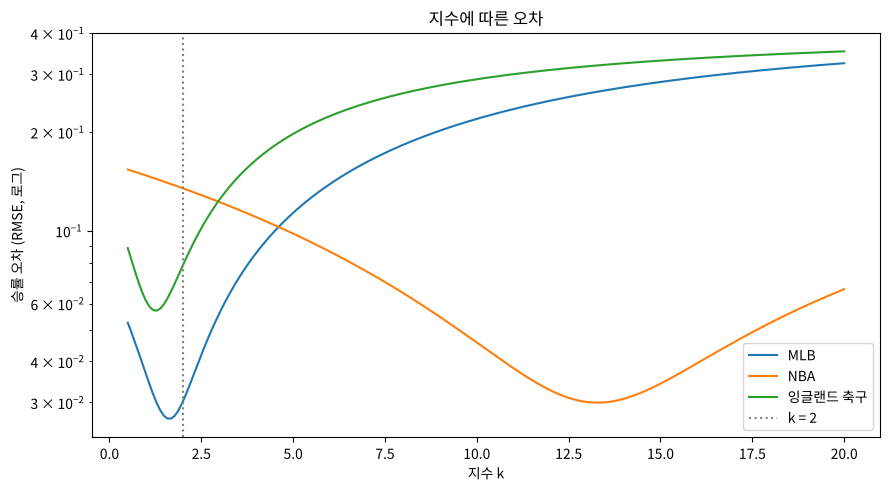

In [4]:
# 오차 곡선: 지수에 따라 오차가 어떻게 변하는지
ks = np.linspace(0.5, 20, 200)
plt.figure(figsize=(9, 5))
for name, t in [("MLB", MLB), ("NBA", NBA), ("잉글랜드 축구", ENG)]:
    plt.plot(ks, [np.sqrt(((t.wpc - pyth(t.F, t.A, k))**2).mean()) for k in ks], label=name)
plt.axvline(2, color="gray", ls=":", label="k = 2")
plt.yscale("log"); plt.xlabel("지수 k"); plt.ylabel("승률 오차 (RMSE, 로그)"); plt.legend(); plt.title("지수에 따른 오차")
plt.tight_layout(); plt.show()

## 결과

- **NBA는 지수가 13 정도일 때 가장 잘 맞았다.** k = 2를 쓰면 시즌 승수 오차가 약 11승이지만, 최적 지수를 쓰면 2.5승으로 줄어든다. 득점이 많은 종목일수록 큰 지수가 필요하다.
- **MLB(1.6)와 축구(1.3)는 2보다 작은 지수가 더 잘 맞았다.** 축구는 k = 2일 때 오차가 3.5경기에서 2.5경기로 줄었다.
- 상관계수는 지수를 바꿔도 거의 같다. 지수는 '순위'가 아니라 '승률 크기'를 맞추는 역할을 하기 때문이다. 그래서 01~03의 회귀분석(R²)은 k = 2로도 높게 나왔지만, 기대 승률 값 자체는 NBA에서 크게 틀렸다.

참고로 알려진 값은 야구 약 1.83, 농구 약 14 내외로, 이번 결과와 같은 방향이다. 한 시즌, 20~92개 팀으로 추정한 값이라 시즌마다 조금씩 달라질 수 있다.